# CS 4372: Assignment 1: Linear Regression Analysis
**Dataset:** Facebook Comment Volume Dataset (UCI ML Repository, id 363)
Task: Regression
**Target:** number of comments a Facebook post receives in the next *H* hours

**Team members:** dal445515 & anw230000
Elizaveta Makhonina & Avizeh Walji

This notebook covers pre-processing, two regularized regression approaches
(`SGDRegressor` & OLS / regularized OLS from
statsmodels), and the supporting plots/tables for the report.


## Setup

In [1]:
# ucimlrepo and statsmodels
!pip install -q ucimlrepo statsmodels


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import statsmodels.api as sm

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")


## 1. Data Loading

DATA_SOURCE just picks where the data comes from — no local file paths either way.

"github" (default - use this), pulls the CSV from a GitHub link.
Make a public GitHub repo
Upload a CSV, e.g. Features_Variant_1.csv
Click Raw on that file, copy the URL
Paste it into RAW_CSV_URL
"ucimlrepo" - left in for reference, but doesn't work for this dataset (id 363)

In [3]:
DATA_SOURCE = "github"
RAW_CSV_URL = "https://raw.githubusercontent.com/elizardmak/4372_Assignment1/refs/heads/main/Features_Variant_1.csv"

COLUMN_NAMES = (
    ["page_likes", "page_checkins", "page_talking_about", "page_category"]
    # 25 aggregate features (min/max/avg/median/std of 5 underlying
    # comment-activity measures). UCI does not document the exact
    # min/max/avg/median/std <-> measure pairing for each of the 25, they're kept as a labeled block rather than individually (mis)named.
    + [f"derived_agg_{i}" for i in range(1, 26)]
    + ["cc1_total_comments", "cc2_last_24h", "cc3_last_48_to_24h",
       "cc4_first_24h_after_post", "cc5_cc2_minus_cc3"]
    + ["base_time", "post_length", "post_share_count",
       "post_promotion_status", "h_local"]
    + [f"post_weekday_{d}" for d in
       ["sun", "mon", "tue", "wed", "thu", "fri", "sat"]]
    + [f"basetime_weekday_{d}" for d in
       ["sun", "mon", "tue", "wed", "thu", "fri", "sat"]]
    + ["target"]
)
assert len(COLUMN_NAMES) == 54

if DATA_SOURCE == "ucimlrepo":
    from ucimlrepo import fetch_ucirepo
    dataset = fetch_ucirepo(id=363)
    df = pd.concat(
        [dataset.data.features.reset_index(drop=True),
         dataset.data.targets.reset_index(drop=True)],
        axis=1,
    )
    assert df.shape[1] == 54, f"Expected 54 columns from ucimlrepo, got {df.shape[1]}"
    df.columns = COLUMN_NAMES
elif DATA_SOURCE == "github":
    assert RAW_CSV_URL, "Set RAW_CSV_URL to your public raw GitHub CSV link."
    df = pd.read_csv(RAW_CSV_URL, header=None, names=COLUMN_NAMES)
else:
    raise ValueError("DATA_SOURCE must be 'ucimlrepo' or 'github'")

print(df.shape)
df.head()


(40949, 54)


,page_likes,page_checkins,page_talking_about,page_category,derived_agg_1,derived_agg_2,derived_agg_3,derived_agg_4,derived_agg_5,derived_agg_6,...,post_weekday_fri,post_weekday_sat,basetime_weekday_sun,basetime_weekday_mon,basetime_weekday_tue,basetime_weekday_wed,basetime_weekday_thu,basetime_weekday_fri,basetime_weekday_sat,target
0,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,0,0,0,0,0,0,0,0,1,0
1,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,0,0,0,0,0,0,0,1,0,0
2,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,1,0,0,0,0,0,0,0,1,0
3,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,1,0,0,1,0,0,0,0,0,0
4,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,0,0,0,0,0,1,0,0,0,0


## 2.1 Pre-processing

In [4]:
df.dtypes.to_frame("dtype")


,dtype
page_likes,int64
page_checkins,int64
page_talking_about,int64
page_category,int64
derived_agg_1,float64
derived_agg_2,float64
derived_agg_3,float64
derived_agg_4,float64
derived_agg_5,float64
derived_agg_6,float64


In [5]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
page_likes,40949.0,1.313814e+06,6.785752e+06,36.0,36734.000000,292911.000000,1.204214e+06,4.869723e+08
page_checkins,40949.0,4.676134e+03,2.059318e+04,0.0,0.000000,0.000000,9.900000e+01,1.863700e+05
page_talking_about,40949.0,4.480025e+04,1.109338e+05,0.0,698.000000,7045.000000,5.026400e+04,6.089942e+06
page_category,40949.0,2.425478e+01,1.995058e+01,1.0,9.000000,18.000000,3.200000e+01,1.060000e+02
derived_agg_1,40949.0,1.586241e+00,2.075317e+01,0.0,0.000000,0.000000,0.000000e+00,2.341000e+03
derived_agg_2,40949.0,4.433339e+02,4.966952e+02,0.0,45.000000,241.000000,7.170000e+02,2.341000e+03
derived_agg_3,40949.0,5.572038e+01,8.693355e+01,0.0,5.527273,23.374101,7.182883e+01,2.341000e+03
derived_agg_4,40949.0,3.564553e+01,6.996023e+01,0.0,2.000000,12.000000,4.200000e+01,2.341000e+03
derived_agg_5,40949.0,6.746415e+01,8.156825e+01,0.0,8.278756,35.069140,1.025550e+02,7.313946e+02
derived_agg_6,40949.0,2.194681e-01,1.005515e+01,0.0,0.000000,0.000000,0.000000e+00,1.923000e+03


### Null / consistency check

In [6]:
print("Missing values per column (nonzero only):")
nulls = df.isnull().sum()
print(nulls[nulls > 0] if nulls.sum() else "none")

n_dupes = df.duplicated().sum()
print(f"Duplicate rows: {n_dupes}")
if n_dupes:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Dropped duplicates, new shape:", df.shape)

# Sanity check: target (a comment count) should never be negative
print("Negative target values:", (df["target"] < 0).sum())


Missing values per column (nonzero only):
none
Duplicate rows: 8


Dropped duplicates, new shape: (40941, 54)
Negative target values: 0


### Categorical attribute: `page_category`

`page_category` is just a number that stands for a category, not a real ranking. So I one-hot encode it instead of treating it like a normal number. There are a ton of categories though, most barely used, so I only keep the TOP_N_CATEGORIES most common ones and dump everything else into "other", otherwise we'd end up with 50+ near empty columns.

In [7]:
TOP_N_CATEGORIES = 15

top_cats = df["page_category"].value_counts().nlargest(TOP_N_CATEGORIES).index
df["page_category_grouped"] = np.where(
    df["page_category"].isin(top_cats),
    df["page_category"].astype(str),
    "other",
)
cat_dummies = pd.get_dummies(
    df["page_category_grouped"], prefix="cat", drop_first=True
)
df = pd.concat(
    [df.drop(columns=["page_category", "page_category_grouped"]), cat_dummies],
    axis=1,
)
print(df.shape)


(40941, 68)


### Train / test split

`TEST_SIZE` sets the split ratio 80/20 by default. I split the data before scaling it, so the scaler only ever sees the training set. If I scaled first and split after, some test-set info would leak into training and make the results look better than they actually are.

In [8]:
TEST_SIZE = 0.2

train_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print("train:", train_df.shape, " test:", test_df.shape)


train: (32752, 68)  test: (8189, 68)


### Distribution of attributes

are the attributes normally distributed? Plotted below for the target and a
handful of representative numeric predictors, with skewness values
(0 = symmetric; the further from 0, the more skewed).

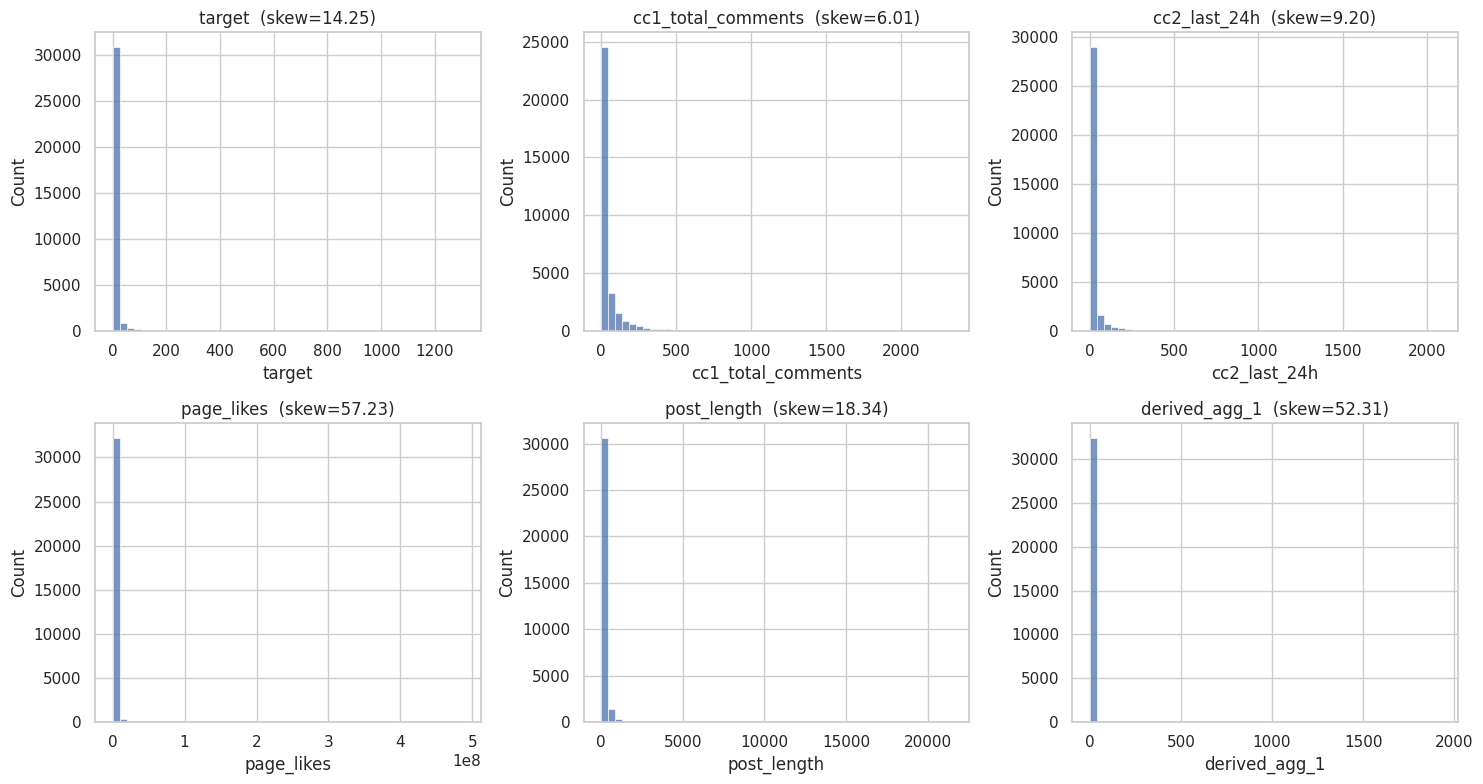

page_likes            57.233294
derived_agg_1         52.308666
post_length           18.342456
target                14.246321
cc2_last_24h           9.203919
cc1_total_comments     6.009625
dtype: float64


In [9]:
cols_to_plot = ["target", "cc1_total_comments", "cc2_last_24h",
                "page_likes", "post_length", "derived_agg_1"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cols_to_plot):
    sns.histplot(train_df[col], bins=50, ax=ax)
    ax.set_title(f"{col}  (skew={skew(train_df[col]):.2f})")
plt.tight_layout()
plt.show()

print(train_df[cols_to_plot].apply(skew).sort_values(ascending=False))


### Correlation

correlation of every numeric attribute with every other attribute and with
the target, both numerically and visually.

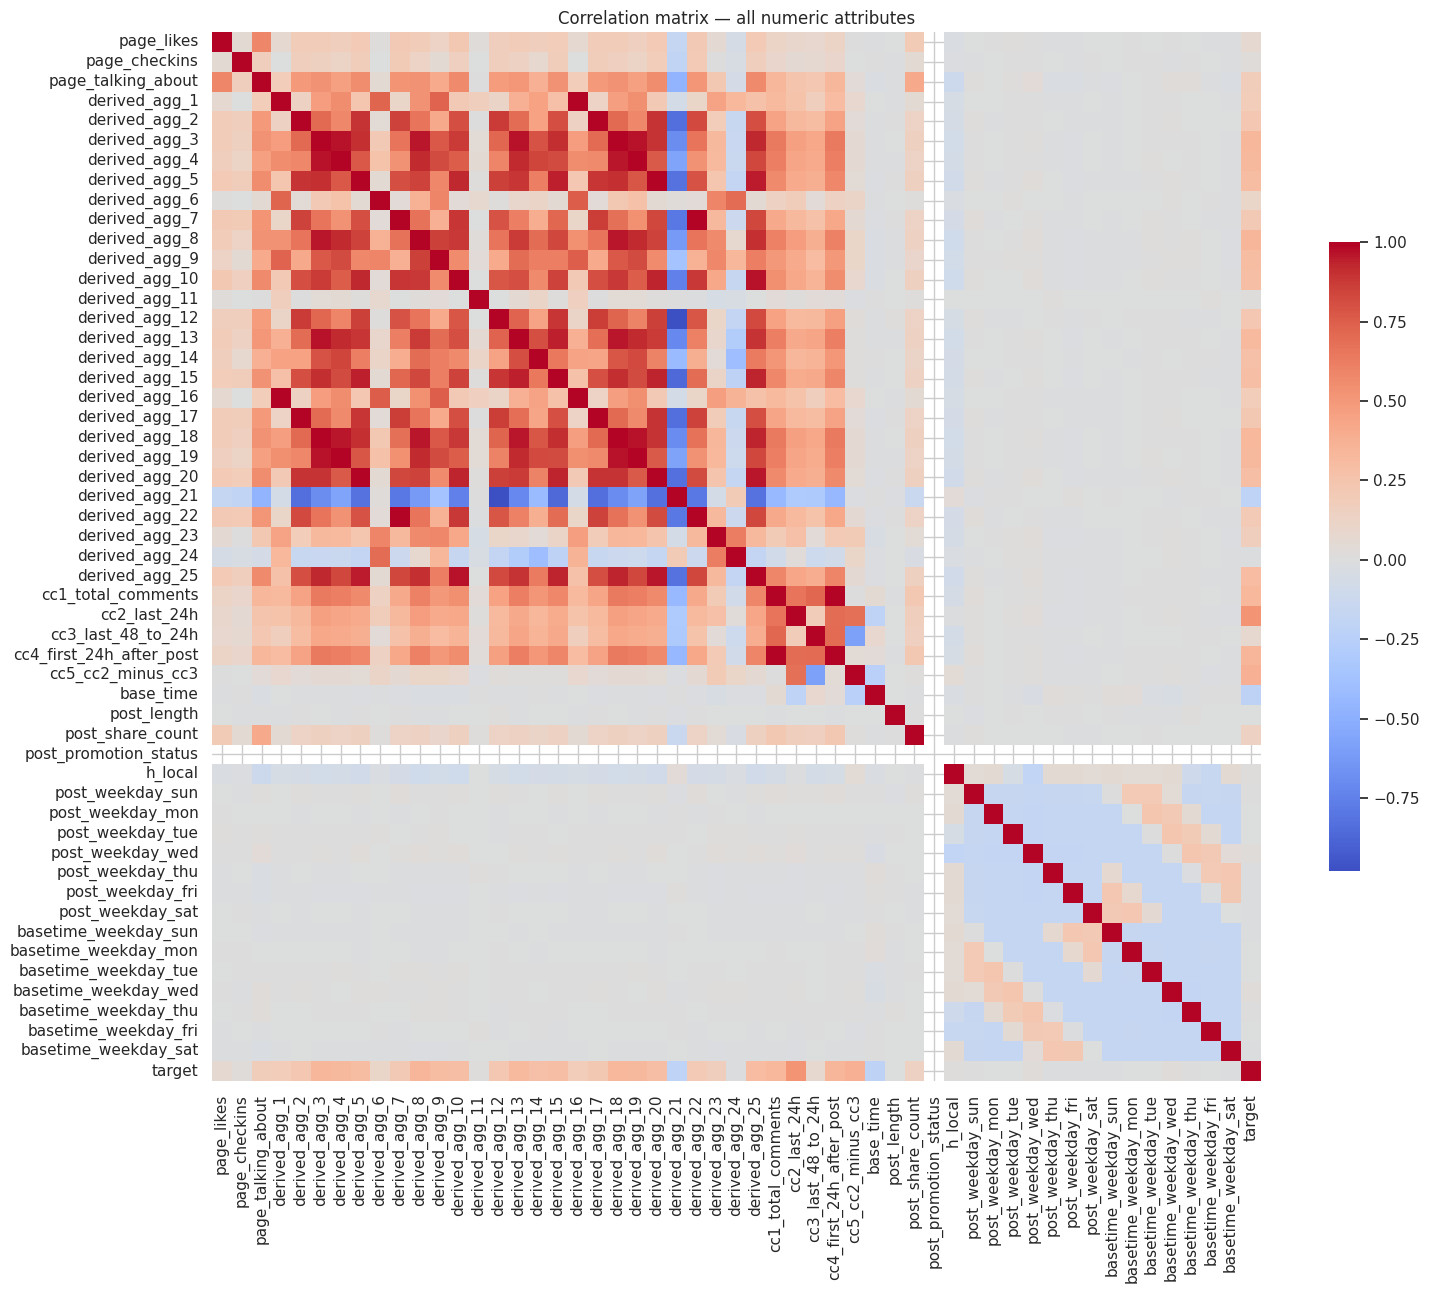

In [10]:
numeric_df = train_df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.6})
plt.title("Correlation matrix — all numeric attributes")
plt.tight_layout()
plt.show()


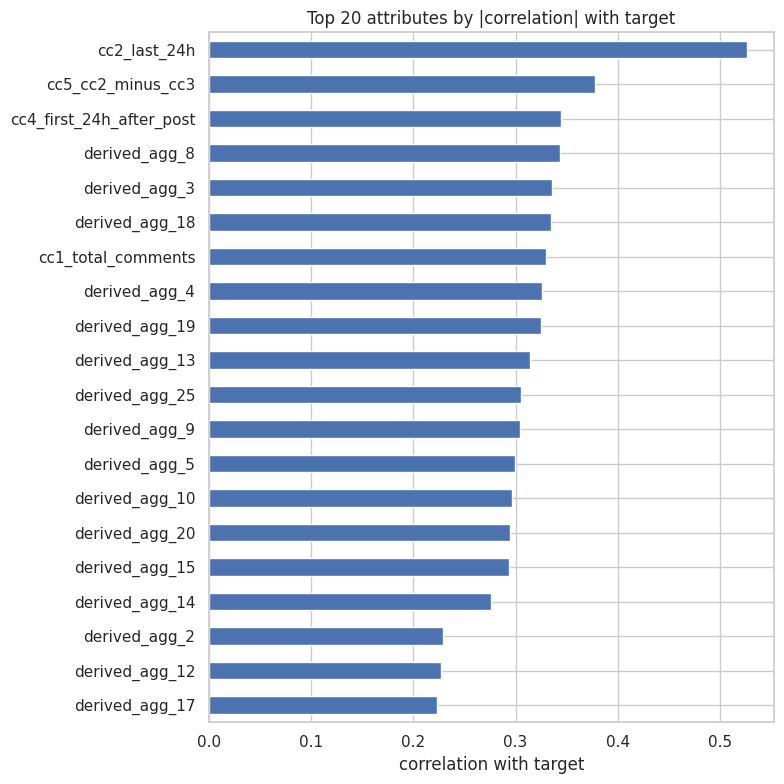

cc2_last_24h                0.526441
cc5_cc2_minus_cc3           0.377487
cc4_first_24h_after_post    0.344628
derived_agg_8               0.343293
derived_agg_3               0.335725
derived_agg_18              0.334291
cc1_total_comments          0.329511
derived_agg_4               0.326246
derived_agg_19              0.324491
derived_agg_13              0.313956
derived_agg_25              0.304944
derived_agg_9               0.303966
derived_agg_5               0.299141
derived_agg_10              0.296470
derived_agg_20              0.294544
derived_agg_15              0.293228
derived_agg_14              0.275794
derived_agg_2               0.228891
derived_agg_12              0.227011
derived_agg_17              0.223357
Name: target, dtype: float64

In [11]:
corr_with_target = (
    corr_matrix["target"].drop("target").sort_values(key=abs, ascending=False)
)

plt.figure(figsize=(8, 8))
corr_with_target.head(20).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 20 attributes by |correlation| with target")
plt.xlabel("correlation with target")
plt.tight_layout()
plt.show()

corr_with_target.head(20)


### Feature selection

Rather than feeding all 60+ columns (53 original + category dummies) into
the model, keeping the `N_FEATURES` most correlated with the target. This also
sidesteps most of the multicollinearity visible in the heatmap above.

In [12]:
N_FEATURES = 10
selected_features = corr_with_target.head(N_FEATURES).index.tolist()
print("Selected features:", selected_features)

X_train = train_df[selected_features]
y_train = train_df["target"]
X_test = test_df[selected_features]
y_test = test_df["target"]
print("train:", X_train.shape, " test:", X_test.shape)


Selected features: ['cc2_last_24h', 'cc5_cc2_minus_cc3', 'cc4_first_24h_after_post', 'derived_agg_8', 'derived_agg_3', 'derived_agg_18', 'cc1_total_comments', 'derived_agg_4', 'derived_agg_19', 'derived_agg_13']
train: (32752, 10)  test: (8189, 10)


## 2.2 Model Construction

### Model 1: GDRegressor (scikit-learn)

Following the assignment instructions, we standardized the data first and evaluated several hyperparameter settings. All tested combinations and their metrics are tracked in the `sgd_log` table below as the required experiment log.

In [13]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train),
                          columns=X_train.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test),
                         columns=X_test.columns, index=X_test.index)


In [14]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    return {
        "train_r2": r2_score(y_tr, pred_tr),
        "test_r2": r2_score(y_te, pred_te),
        "train_rmse": mean_squared_error(y_tr, pred_tr) ** 0.5,
        "test_rmse": mean_squared_error(y_te, pred_te) ** 0.5,
        "test_mae": mean_absolute_error(y_te, pred_te),
    }

# baseline: SGDRegressor with all default hyperparameters
baseline_sgd = SGDRegressor(random_state=RANDOM_STATE)
baseline_sgd.fit(X_train_s, y_train)
baseline_metrics = evaluate(baseline_sgd, X_train_s, y_train, X_test_s, y_test)
print("Baseline (default hyperparameters):", baseline_metrics)


Baseline (default hyperparameters): {'train_r2': 0.2922989726015731, 'test_r2': 0.306373220322838, 'train_rmse': 30.528166002220242, 'test_rmse': 26.762939763808358, 'test_mae': 6.939107213502846}


In [15]:
# penalty/alpha/l1_ratio control regularization strength & type;
# learning_rate/eta0/max_iter/loss control the optimization itself.
sgd_configs = [
    dict(penalty="l2",         alpha=0.0001, l1_ratio=0.15, learning_rate="invscaling", eta0=0.01, max_iter=1000, loss="squared_error"),
    dict(penalty="l1",         alpha=0.0001, l1_ratio=0.15, learning_rate="invscaling", eta0=0.01, max_iter=1000, loss="squared_error"),
    dict(penalty="elasticnet", alpha=0.001,  l1_ratio=0.5,  learning_rate="invscaling", eta0=0.01, max_iter=1000, loss="squared_error"),
    dict(penalty="elasticnet", alpha=0.01,   l1_ratio=0.85, learning_rate="adaptive",   eta0=0.01, max_iter=2000, loss="huber"),
    dict(penalty="l2",         alpha=0.001,  l1_ratio=0.15, learning_rate="optimal",    eta0=0.01, max_iter=1000, loss="squared_error"),
    dict(penalty="l2",         alpha=0.1,    l1_ratio=0.15, learning_rate="invscaling", eta0=0.01, max_iter=1000, loss="squared_error"),
    dict(penalty="l1",         alpha=0.01,   l1_ratio=0.15, learning_rate="invscaling", eta0=0.05, max_iter=1500, loss="huber"),
]

sgd_rows = []
for cfg in sgd_configs:
    model = SGDRegressor(random_state=RANDOM_STATE, **cfg)
    model.fit(X_train_s, y_train)
    metrics = evaluate(model, X_train_s, y_train, X_test_s, y_test)
    sgd_rows.append({**cfg, **metrics})

sgd_log = pd.DataFrame(sgd_rows).sort_values("test_r2", ascending=False).reset_index(drop=True)
sgd_log


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_stochastic_gradient.py:1612: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


,penalty,alpha,l1_ratio,learning_rate,eta0,max_iter,loss,train_r2,test_r2,train_rmse,test_rmse,test_mae
0,elasticnet,0.0010,0.50,invscaling,0.01,1000,squared_error,2.923748e-01,3.064778e-01,30.526530,26.760922,6.936915
1,l1,0.0001,0.15,invscaling,0.01,1000,squared_error,2.923259e-01,3.063999e-01,30.527584,26.762425,6.938659
2,l2,0.0001,0.15,invscaling,0.01,1000,squared_error,2.922990e-01,3.063732e-01,30.528166,26.762940,6.939107
3,l2,0.1000,0.15,invscaling,0.01,1000,squared_error,2.898911e-01,3.062287e-01,30.580057,26.765729,6.852854
4,l1,0.0100,0.15,invscaling,0.05,1500,huber,1.689549e-01,1.789165e-01,33.081721,29.118201,5.391799
5,elasticnet,0.0100,0.85,adaptive,0.01,2000,huber,1.256835e-01,1.331008e-01,33.932052,29.919559,5.688598
6,l2,0.0010,0.15,optimal,0.01,1000,squared_error,-6.947375e+06,-8.444246e+06,95650.269756,93379.457671,40765.219553


Best config: {'penalty': 'elasticnet', 'alpha': 0.001, 'l1_ratio': 0.5, 'learning_rate': 'invscaling', 'eta0': 0.01, 'max_iter': 1000, 'loss': 'squared_error'}
Best metrics: {'train_r2': 0.2923748115768109, 'test_r2': 0.3064777963024857, 'train_rmse': 30.526530221879764, 'test_rmse': 26.76092220463666, 'test_mae': 6.936915466544848}


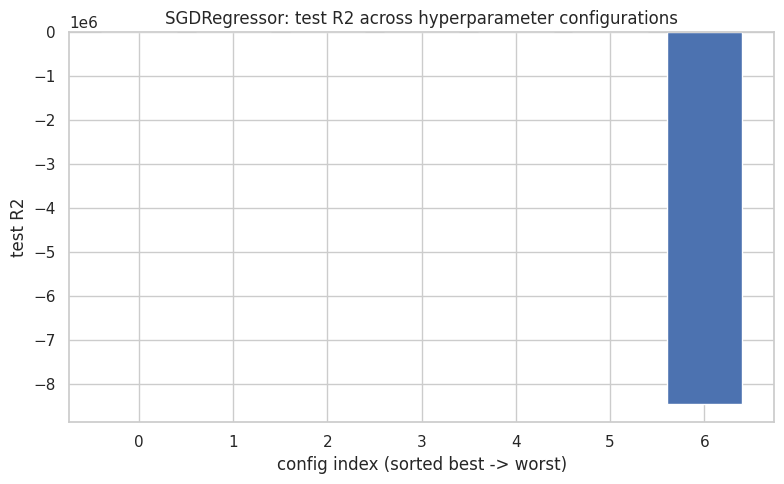

In [16]:
best_cfg = sgd_log.iloc[0][["penalty", "alpha", "l1_ratio", "learning_rate", "eta0", "max_iter", "loss"]].to_dict()
best_sgd = SGDRegressor(random_state=RANDOM_STATE, **best_cfg)
best_sgd.fit(X_train_s, y_train)
best_sgd_metrics = evaluate(best_sgd, X_train_s, y_train, X_test_s, y_test)
print("Best config:", best_cfg)
print("Best metrics:", best_sgd_metrics)

plt.figure(figsize=(8, 5))
plt.bar(range(len(sgd_log)), sgd_log["test_r2"])
plt.xlabel("config index (sorted best -> worst)")
plt.ylabel("test R2")
plt.title("SGDRegressor: test R2 across hyperparameter configurations")
plt.tight_layout()
plt.show()


### Model 2: OLS and Regularized OLS (statsmodels)

First, we ran standard unregularized OLS with .fit() to review the complete diagnostic summary. We then compared those results against regularized OLS using .fit_regularized(), sweeping through different penalty types from pure Ridge (L1_wt=0) to pure Lasso (L1_wt=1) and ElasticNet combinations.

In [17]:
X_train_c = sm.add_constant(X_train_s)
X_test_c = sm.add_constant(X_test_s)

ols_model = sm.OLS(y_train.values, X_train_c).fit()
print(ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.302
Model:                            OLS   Adj. R-squared:                  0.302
Method:                 Least Squares   F-statistic:                     1419.
Date:                Wed, 16 Sep 2026   Prob (F-statistic):               0.00
Time:                        13:42:59   Log-Likelihood:            -1.5821e+05
No. Observations:               32752   AIC:                         3.164e+05
Df Residuals:                   32741   BIC:                         3.165e+05
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

In [18]:
ols_pred_test = ols_model.predict(X_test_c)
ols_metrics = {
    "test_r2": r2_score(y_test, ols_pred_test),
    "test_rmse": mean_squared_error(y_test, ols_pred_test) ** 0.5,
    "test_mae": mean_absolute_error(y_test, ols_pred_test),
}
print(ols_metrics)


{'test_r2': 0.3194077271108584, 'test_rmse': 26.510285055025523, 'test_mae': 6.495279002986884}


In [19]:
# fit_regularized doesn't provide standard errors/p-values (no closed-form
# inference under an L1 penalty), so metrics are computed manually here.
reg_rows = []
for alpha in [0.0, 0.001, 0.01, 0.1, 1.0]:
    for l1_wt in [0.0, 0.5, 1.0]:
        res = sm.OLS(y_train.values, X_train_c).fit_regularized(alpha=alpha, L1_wt=l1_wt)
        pred_tr = X_train_c.values @ res.params
        pred_te = X_test_c.values @ res.params
        reg_rows.append({
            "alpha": alpha, "L1_wt": l1_wt,
            "train_r2": r2_score(y_train, pred_tr),
            "test_r2": r2_score(y_test, pred_te),
            "test_rmse": mean_squared_error(y_test, pred_te) ** 0.5,
            "test_mae": mean_absolute_error(y_test, pred_te),
        })

ols_reg_log = pd.DataFrame(reg_rows).sort_values("test_r2", ascending=False).reset_index(drop=True)
ols_reg_log


,alpha,L1_wt,train_r2,test_r2,test_rmse,test_mae
0,0.001,0.0,0.301231,0.319883,26.501030,6.480149
1,0.000,0.0,0.302321,0.319408,26.510285,6.495279
2,0.000,0.5,0.299149,0.316692,26.563117,6.487232
3,0.000,1.0,0.299149,0.316692,26.563117,6.487232
4,0.010,0.0,0.298674,0.316683,26.563301,6.446326
5,0.001,0.5,0.299103,0.316643,26.564070,6.484851
6,0.001,1.0,0.299128,0.316642,26.564094,6.486996
7,0.010,0.5,0.298677,0.316217,26.572354,6.466300
8,0.010,1.0,0.298778,0.315829,26.579894,6.494358
9,0.100,1.0,0.298035,0.314758,26.600692,6.435546


In [20]:
best_reg_row = ols_reg_log.iloc[0]
best_ols_reg = sm.OLS(y_train.values, X_train_c).fit_regularized(
    alpha=best_reg_row["alpha"], L1_wt=best_reg_row["L1_wt"]
)
best_ols_reg_pred = X_test_c.values @ best_ols_reg.params
print("Best regularized OLS config:", best_reg_row[["alpha", "L1_wt"]].to_dict())
print("coefficients:")
print(pd.Series(best_ols_reg.params, index=X_train_c.columns))


Best regularized OLS config: {'alpha': 0.001, 'L1_wt': 0.0}
coefficients:
const                        7.407376
cc2_last_24h                19.300511
cc5_cc2_minus_cc3            0.814451
cc4_first_24h_after_post   -11.753862
derived_agg_8                3.553820
derived_agg_3               20.202855
derived_agg_18             -21.441118
cc1_total_comments           6.650364
derived_agg_4                9.915885
derived_agg_19              -8.821962
derived_agg_13               3.409931
dtype: float64


## 2.3 Result Analysis

Side-by-side comparison of all four models: SGDRegressor (default vs. best
tuned) and OLS (unregularized vs. best regularized).

In [21]:
comparison = pd.DataFrame([
    {"model": "SGD (default)", "test_r2": baseline_metrics["test_r2"], "test_rmse": baseline_metrics["test_rmse"], "test_mae": baseline_metrics["test_mae"]},
    {"model": "SGD (tuned)", "test_r2": best_sgd_metrics["test_r2"], "test_rmse": best_sgd_metrics["test_rmse"], "test_mae": best_sgd_metrics["test_mae"]},
    {"model": "OLS (unregularized)", "test_r2": ols_metrics["test_r2"], "test_rmse": ols_metrics["test_rmse"], "test_mae": ols_metrics["test_mae"]},
    {"model": "OLS (best regularized)", "test_r2": r2_score(y_test, best_ols_reg_pred),
     "test_rmse": mean_squared_error(y_test, best_ols_reg_pred) ** 0.5,
     "test_mae": mean_absolute_error(y_test, best_ols_reg_pred)},
])
comparison


,model,test_r2,test_rmse,test_mae
0,SGD (default),0.306373,26.762940,6.939107
1,SGD (tuned),0.306478,26.760922,6.936915
2,OLS (unregularized),0.319408,26.510285,6.495279
3,OLS (best regularized),0.319883,26.501030,6.480149


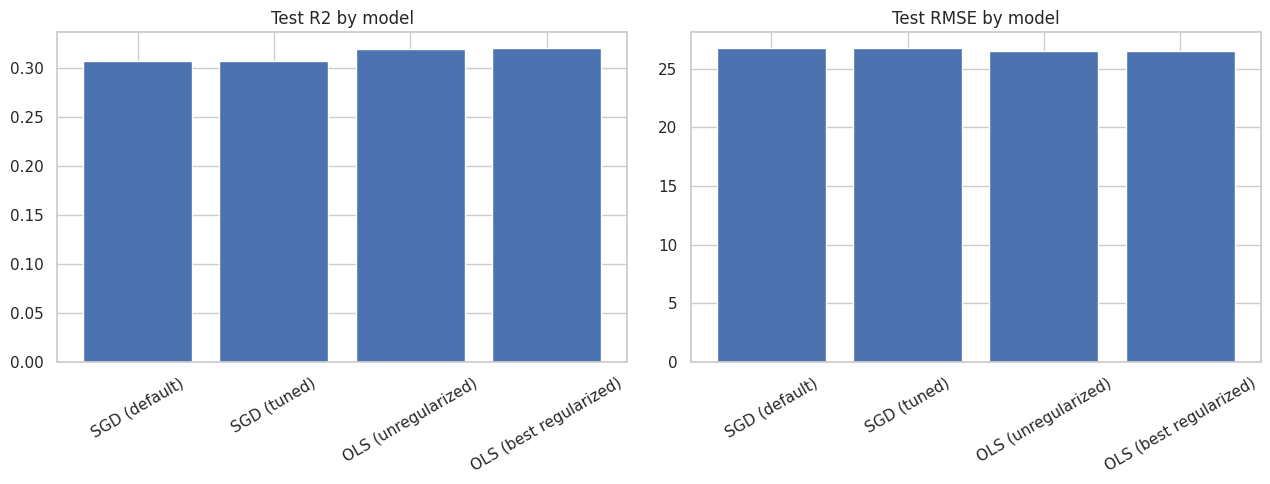

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(comparison["model"], comparison["test_r2"])
axes[0].set_title("Test R2 by model")
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(comparison["model"], comparison["test_rmse"])
axes[1].set_title("Test RMSE by model")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


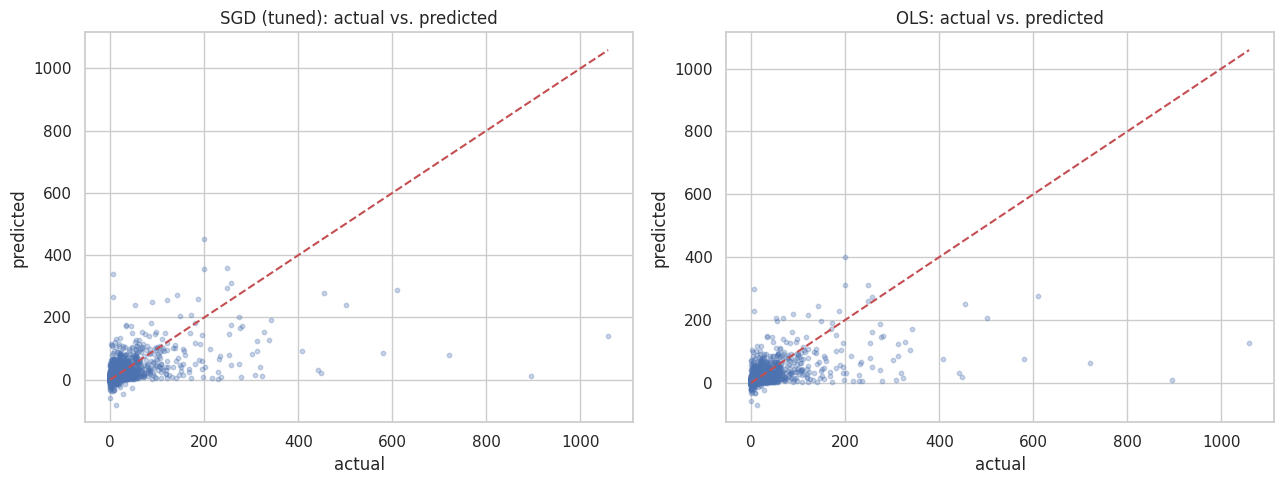

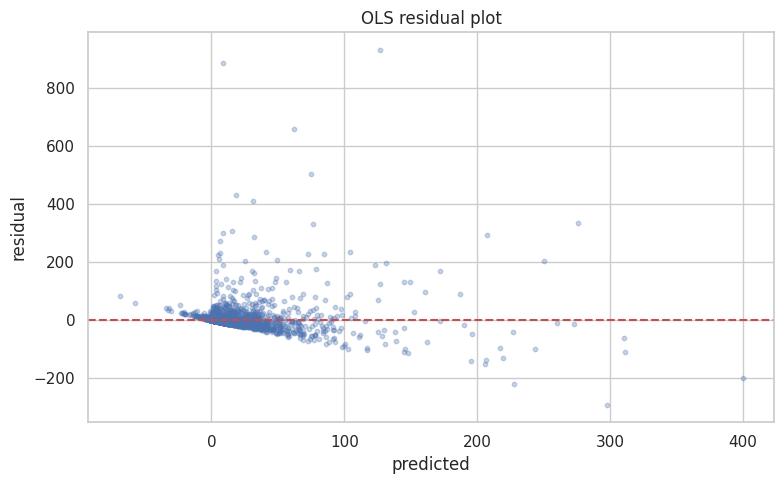

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, best_sgd.predict(X_test_s), alpha=0.3, s=10)
lims = [0, max(y_test.max(), best_sgd.predict(X_test_s).max())]
axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("actual"); axes[0].set_ylabel("predicted")
axes[0].set_title("SGD (tuned): actual vs. predicted")

axes[1].scatter(y_test, ols_pred_test, alpha=0.3, s=10)
axes[1].plot(lims, lims, "r--")
axes[1].set_xlabel("actual"); axes[1].set_ylabel("predicted")
axes[1].set_title("OLS: actual vs. predicted")
plt.tight_layout()
plt.show()

residuals = y_test.values - ols_pred_test.values
plt.figure(figsize=(8, 5))
plt.scatter(ols_pred_test, residuals, alpha=0.3, s=10)
plt.axhline(0, color="r", linestyle="--")
plt.xlabel("predicted"); plt.ylabel("residual")
plt.title("OLS residual plot")
plt.tight_layout()
plt.show()


## Assumptions made:

- Dataset: Used the UCI Facebook Comment Volume dataset (ID 363, Variant 1), containing 40,949 initial records.
- Feature Processing: One-hot encoded the 15 most common page_category values (grouping the rest under "other") and selected the top 10 numerical features based on correlation with the target.
- Data Preparation: Used an 80/20 train/test split (random_state=42) and fit the scaler strictly on training data to prevent data leakage.
- Feature Grouping: Kept derived_agg_1...25 under their original column names because exact attribute definitions are not provided in the UCI source.